# A neural network that forecasts housing affordability

**Group 8:** Akshat Dayal, Bhavini Manot, Bo De Roeck · IAAC MaAI 2026–27 · AI Methods I · Neural networks
**Track:** A1 (MLP on tables)
**Model on Hugging Face:** https://huggingface.co/iaac-maai/day4-group8-affordability-mlp

# 0. Introduction and problem definition

Our earlier supervised model, a Ridge regression, forecasts **next year's housing affordability** of a country from the indicators known this year. Today we train a **neural network** (a multi-layer perceptron, MLP) on exactly the same problem, with exactly the same data, inputs, target and test set, and we check honestly whether it does better.

**Where this fits in our project.** All our work uses one dataset (housing affordability in 26 countries, 1977–2024) and builds step by step:

| Step | What it did | Result we reuse here |
|---|---|---|
| **1. Data cleaning and exploration** ([repository](https://github.com/iaac-maai/Group8-day1-assignment)) | Cleaned the raw data, removed hyperinflation artefacts and leaking features, engineered lags and yearly changes | The model-ready table: our inputs |
| **2. Forecasting with supervised learning** ([model](https://huggingface.co/iaac-maai/day2-group8-affordability)) | Compared seven models with time-based cross-validation; a Ridge regression forecasts next year's affordability | The **baseline** to beat, with its inputs, preprocessing and test set |
| **3. Market regimes with clustering** ([dataset](https://huggingface.co/datasets/iaac-maai/day3-group8-housing-market-regimes)) | K-Means on price, income and affordability dynamics: four phases (affordable steady growth, price boom, expensive plateau, price correction) for every country-year | The **regime** of every country-year, used in section 6.2 to see **in which market phases** the forecasts fail |
| **4. This notebook: a neural-network forecaster** | An MLP on the same problem as step 2 | Is a neural network better than the Ridge forecaster, and where do both fail? |

**The three questions of the brief:**

1. **Who would use this model, and for what?** A housing policy analyst at a ministry, central bank or international organisation who follows many countries and wants a **one-year-ahead early warning**: "affordability in country X is likely to get about 4% worse next year", before the official figures are published.
2. **What does a mistake cost?** Under-forecasting a deterioration (the model says "stable", housing actually becomes much less affordable) delays a policy response and is the costlier mistake. Over-forecasting creates a false alarm that an analyst checks against other sources. Both are measured by the **forecast error**: we report the MAE in index points, the share of forecasts within ±5%, and look separately at the largest misses.
3. **What would be good enough?** The network is only useful if it beats (a) the naive rule **"next year = this year"** and (b) our **Ridge forecaster** on the **same test years (2015–2024)**. Result to beat: **test MAE 3.28 index points, R² 0.83 (log scale), 83% of forecasts within ±5%**.

**The data:** `housing_affordability_model_ready.csv`, cleaned in our [data cleaning and exploration repository](https://github.com/iaac-maai/Group8-day1-assignment) from the Kaggle notebook [Forecasting housing affordability](https://www.kaggle.com/code/tolstoyjustin/forecasting-housing-affordability) (data licence CC BY-SA 4.0). **One example = one country in one year** (e.g. "Spain, 2006"): 1,210 rows, 26 countries, 1977–2024, with real house price and income indexes, their yearly changes, past affordability values, region and decade. **Affordability** = real house price index ÷ real disposable income index × 100 (higher = less affordable). It is an **index**: it shows change over time within one country, not a comparable price level between countries.

In [1]:
# Only needed in Google Colab or a new environment: remove the "#" and run this cell once.
# %pip install torch torchinfo pandas scikit-learn matplotlib seaborn joblib

In [2]:
import copy
import shutil
import time
import urllib.request
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchinfo import summary

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# --- Folders: the notebook lives in notebook/, everything else is one level up -------------
DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR]:
    folder.mkdir(exist_ok=True)

# --- Settings ------------------------------------------------------------------------------
pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
SEED = 42                       # the same seed everywhere (the earlier steps used 42 too)
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = "cpu"                  # a network of a few thousand weights trains in seconds on any CPU
print(f"PyTorch {torch.__version__}, device: {DEVICE}")


def save_fig(name, also_model_card=False):
    # Save the current figure in figures/ (README) and, if asked, in models/ (model card on Hugging Face)
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    if also_model_card:
        shutil.copy(path, MODEL_DIR / f"{name}.png")
    print(f"Figure saved to {path}" + (" (and models/)" if also_model_card else ""))

PyTorch 2.14.1+cpu, device: cpu


# 1. Data and splits

## 1.1 Load the data

The cleaned file is downloaded once from our data-cleaning repository into `data/` (which is not committed). We prepare the inputs **exactly as for the Ridge forecaster**, so the comparison is fair:
- **Target:** `log10(affordability_next)`. Affordability is skewed, so we work on the log scale; an error of 0.01 in log10 is about 2.3%.
- **Inputs (17 columns):** the numeric indicators of this year (indexes, yearly changes, lags, 3-year average, data-cleaning flags), `log_affordability`, `region` (one text column) and `decade` (ordinal).
- **Left out:** the target, `iso` (the country code: with it the model could memorise each country's level) and two columns that are constant in this file.

In [3]:
DATA_URL = "https://raw.githubusercontent.com/iaac-maai/Group8-day1-assignment/main/data/housing_affordability_model_ready.csv"
DATA_FILE = DATA_DIR / "housing_affordability_model_ready.csv"
if not DATA_FILE.exists():
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

df = pd.read_csv(DATA_FILE).sort_values(["year", "iso"]).reset_index(drop=True)   # time order, as for the Ridge forecaster

region_cols = [c for c in df.columns if c.startswith("region_")]
X = df.drop(columns=["affordability_next", "iso", "data_reliable", "is_latest_year"] + region_cols)
X["log_affordability"] = np.log10(df["affordability"])
X["region"] = df[region_cols].idxmax(axis=1).str.replace("region_", "")
X["decade"] = df["decade"].astype(str) + "s"
y = np.log10(df["affordability_next"])

FEATURE_COLS = X.columns.tolist()
print(df.shape, "->", X.shape[1], "input columns:", FEATURE_COLS)
df[["iso", "year", "affordability", "real_hpi_change_pct", "real_income_change_pct", "affordability_next"]].head()

(1210, 29) -> 17 input columns: ['year', 'decade', 'affordability', 'real_house_price_index', 'real_personal_disposable_income', 'real_hpi_change_pct', 'real_income_change_pct', 'affordability_lag1', 'affordability_lag2', 'affordability_3yr_avg', 'nominal_zero', 'hyperinflation_country', 'price_shock_up', 'price_shock_down', 'gfc_period', 'log_affordability', 'region']


,iso,year,affordability,real_hpi_change_pct,real_income_change_pct,affordability_next
0,AUS,1977,39.0488,-1.0162,-0.2907,38.0612
1,BEL,1977,75.3800,11.1576,-1.3349,80.6610
2,CAN,1977,49.9526,-5.8318,-0.3970,49.3942
3,CHE,1977,96.6745,-0.5392,1.2443,97.4368
4,COL,1977,274.7984,-11.6239,3.4117,249.7697


## 1.2 Split before anything else

Our rows are **years**, so we split **by time**, as for the Ridge forecaster. Neighbouring years of one country are almost identical: a random split would let the model "see the future" (leakage).

| Set | Years | Used for |
|---|---|---|
| **Training** | 1977–2009 | Learning the weights |
| **Validation** | 2010–2014 | Watching the training curves, early stopping, comparing the experiments of section 5 |
| **Test** | 2015–2024 | Used **once**, in section 6. **The same test set as the Ridge forecaster.** |

Training + validation together are exactly the Ridge forecaster's training set (1977–2014). The network needs a validation set to decide when to stop, so it learns from 33 years; the Ridge forecaster learned from all 38. We come back to this in section 2.

In [4]:
is_train = df["year"] < 2015                       # the Ridge forecaster's training set (1977-2014)
is_fit = df["year"] < 2010                         # what the network learns from
is_val = is_train & ~is_fit                        # 2010-2014
is_test = ~is_train                                # 2015-2024: the Ridge forecaster's test set

for name, mask in [("training (fit)", is_fit), ("validation", is_val), ("test", is_test)]:
    years = df.loc[mask, "year"]
    print(f"{name:>15}: {mask.sum():>4} rows, {years.min()}-{years.max()}, {df.loc[mask, 'iso'].nunique()} countries")

 training (fit):  820 rows, 1977-2009, 26 countries
     validation:  130 rows, 2010-2014, 26 countries
           test:  260 rows, 2015-2024, 26 countries


## 1.3 Look at the data

What has to be learned: affordability moves **slowly** within each country, so next year is mostly this year. The interesting part is the **change** from one year to the next (right), which is usually within ±5% but has fat tails (booms and crashes).

Figure saved to ..\figures\01_data_and_splits.png


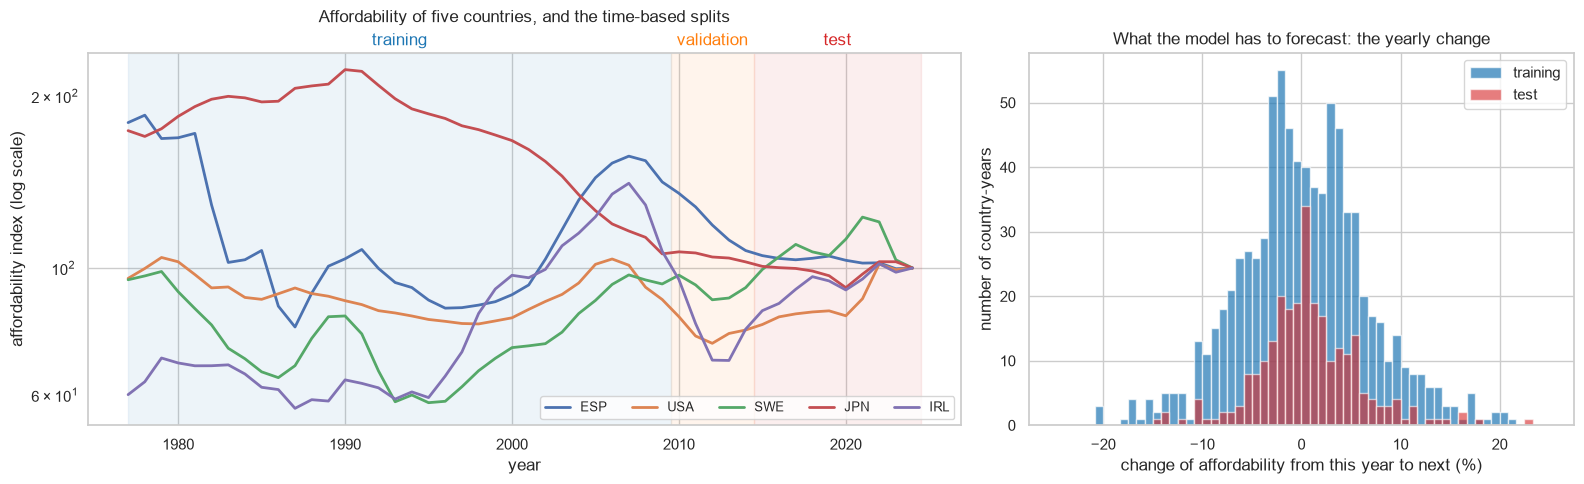

Yearly change: median 0.1%, within ±5% in 65% of country-years; training std 6.7%, test std 5.2%


In [5]:
change_pct = (df["affordability_next"] / df["affordability"] - 1) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.6, 1]})
for iso in ["ESP", "USA", "SWE", "JPN", "IRL"]:
    part = df[df["iso"] == iso]
    axes[0].plot(part["year"], part["affordability"], lw=2, label=iso)
for (start, end), color, label in [((1977, 2009.5), "tab:blue", "training"), ((2009.5, 2014.5), "tab:orange", "validation"),
                                   ((2014.5, 2024.5), "tab:red", "test")]:
    axes[0].axvspan(start, end, color=color, alpha=0.08)
    axes[0].text((start + end) / 2, 1.02, label, transform=axes[0].get_xaxis_transform(), ha="center", color=color)
axes[0].set_yscale("log")
axes[0].set_xlabel("year")
axes[0].set_ylabel("affordability index (log scale)")
axes[0].set_title("Affordability of five countries, and the time-based splits", pad=22)
axes[0].legend(ncol=5, loc="lower right", fontsize=9)

axes[1].hist(change_pct[is_fit], bins=60, range=(-25, 25), color="tab:blue", alpha=0.7, label="training")
axes[1].hist(change_pct[is_test], bins=60, range=(-25, 25), color="tab:red", alpha=0.6, label="test")
axes[1].set_xlabel("change of affordability from this year to next (%)")
axes[1].set_ylabel("number of country-years")
axes[1].set_title("What the model has to forecast: the yearly change")
axes[1].legend()
plt.tight_layout()
save_fig("01_data_and_splits")
plt.show()

print(f"Yearly change: median {change_pct.median():.1f}%, within ±5% in {(change_pct.abs() <= 5).mean():.0%} of country-years; "
      f"training std {change_pct[is_fit].std():.1f}%, test std {change_pct[is_test].std():.1f}%")

- **Five countries, five histories** (left, log scale): Spain and Ireland boom until 2007 and fall back, Japan's affordability falls for 25 years after its 1990 peak, Sweden rises almost continuously since 1996. All series are indexes with **2024 = 100**, which is why they meet on the right: levels cannot be compared between countries, only movements.
- **The yearly change** (right) has a median of **+0.1%** and is within ±5% in **65%** of country-years, but it has long tails: booms and crashes of ±15–20%.
- **The test years are calmer than the training years:** the standard deviation of the yearly change is **6.7%** in 1977–2009 and **5.2%** in 2015–2024. The training years contain the big booms and crashes (Nordic banking crises around 1990, 2008), so the model has seen larger swings than it is tested on, except for the 2021–2023 shock (section 6.1).

## 1.4 Preprocessing and tensors

The same preprocessing as the Ridge forecaster (median imputation + scaling for numbers, one-hot for `region`, ordinal for `decade`), **fitted on the training years only**: 17 columns become 26 numbers per country-year.

**One design choice (tested in section 5):** the network does **not** predict next year's level directly. It predicts the **change** `log10(next) − log10(this year)`, and we add this year's value back. "Next year = this year" is then the network's starting point, and its job is only to learn the correction. Its final output is still `log10(affordability_next)`, the same target as Day 2. We standardise the change with its training mean and standard deviation, so the network's output is of order 1.

In [6]:
numeric_cols = X.columns.drop(["region", "decade"]).tolist()
decade_order = ["1970s", "1980s", "1990s", "2000s", "2010s", "2020s"]


def make_preprocess():
    # the Ridge forecaster's ColumnTransformer, unchanged
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric_cols),
        ("region", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore"))]), ["region"]),
        ("decade", OrdinalEncoder(categories=[decade_order], handle_unknown="use_encoded_value", unknown_value=-1), ["decade"]),
    ])


preprocess = make_preprocess().fit(X[is_fit])       # statistics from the training years only
INPUT_NAMES = [n.split("__")[1] for n in preprocess.get_feature_names_out()]


def to_tensor(values):
    return torch.tensor(np.asarray(values, dtype=np.float32))


A = {name: to_tensor(preprocess.transform(X[mask])) for name, mask in [("fit", is_fit), ("val", is_val), ("test", is_test)]}
log_now = {name: X.loc[mask, "log_affordability"].to_numpy() for name, mask in [("fit", is_fit), ("val", is_val), ("test", is_test)]}
y_log = {name: y[mask].to_numpy() for name, mask in [("fit", is_fit), ("val", is_val), ("test", is_test)]}

# Target of the network: the standardised change of log10 affordability (statistics of the training years)
delta_fit = y_log["fit"] - log_now["fit"]
TARGET_MEAN, TARGET_STD = float(delta_fit.mean()), float(delta_fit.std())
T = {name: to_tensor((y_log[name] - log_now[name] - TARGET_MEAN) / TARGET_STD).unsqueeze(1) for name in ["fit", "val"]}

print(f"inputs: {len(INPUT_NAMES)} numbers per country-year; tensors:", {k: tuple(v.shape) for k, v in A.items()})
print(f"target change (log10): mean {TARGET_MEAN:+.4f}, std {TARGET_STD:.4f}")

inputs: 26 numbers per country-year; tensors: {'fit': (820, 26), 'val': (130, 26), 'test': (260, 26)}
target change (log10): mean -0.0005, std 0.0291


# 2. Baselines

Two baselines, both evaluated on the validation years now and on the test years in section 6:
- **"Next year = this year"** (persistence): no model at all. Affordability changes slowly, so this is a strong rule.
- **Our Ridge forecaster** (our earlier supervised model): `Ridge(alpha=1)` with the same preprocessing, retrained here exactly as before (same columns, same `alpha`, same training years 1977–2014; the published version is [iaac-maai/day2-group8-affordability](https://huggingface.co/iaac-maai/day2-group8-affordability)). For the validation comparison we also fit the same Ridge on 1977–2009 only, the years the network learns from.

In [7]:
def ridge_model():
    return Pipeline([("prep", make_preprocess()), ("model", Ridge(alpha=1.0))])


ridge_main = ridge_model().fit(X[is_train], y[is_train])        # the published Ridge forecaster: trained on 1977-2014
ridge_fit = ridge_model().fit(X[is_fit], y[is_fit])             # the same, trained on 1977-2009 only

baseline_val = pd.DataFrame({
    "validation MAE (log10)": {
        "Next year = this year": mean_absolute_error(y_log["val"], log_now["val"]),
        "Ridge forecaster, trained 1977-2009": mean_absolute_error(y_log["val"], ridge_fit.predict(X[is_val])),
    }})
baseline_val["≈ error (%)"] = (10 ** baseline_val["validation MAE (log10)"] - 1) * 100
baseline_val

,validation MAE (log10),≈ error (%)
Next year = this year,0.0141,3.3075
"Ridge forecaster, trained 1977-2009",0.0104,2.4138


# 3. The model and its training

## 3.1 The architecture

An `nn.Sequential` MLP, as in notebook 01: **26 inputs → 32 → 32 → 1 output**, with ReLU activations and dropout between the layers. The output is one number: the standardised change of log10 affordability.

In [8]:
HIDDEN, DROPOUT = 32, 0.2


def make_mlp(n_inputs=len(INPUT_NAMES), hidden=HIDDEN, dropout=DROPOUT, layers=2):
    blocks, width = [], n_inputs
    for _ in range(layers):
        blocks += [nn.Linear(width, hidden), nn.ReLU(), nn.Dropout(dropout)]
        width = hidden
    return nn.Sequential(*blocks, nn.Linear(width, 1))


torch.manual_seed(SEED)
print(summary(make_mlp(), input_data=A["fit"][:32], col_names=["input_size", "output_size", "num_params"], verbose=0))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                               [32, 26]                  [32, 1]                   --
├─Linear: 1-1                            [32, 26]                  [32, 32]                  864
├─ReLU: 1-2                              [32, 32]                  [32, 32]                  --
├─Dropout: 1-3                           [32, 32]                  [32, 32]                  --
├─Linear: 1-4                            [32, 32]                  [32, 32]                  1,056
├─ReLU: 1-5                              [32, 32]                  [32, 32]                  --
├─Dropout: 1-6                           [32, 32]                  [32, 32]                  --
├─Linear: 1-7                            [32, 32]                  [32, 1]                   33
Total params: 1,953
Trainable params: 1,953
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.06
Input size (MB): 0.

## 3.2 The training loop

The loop of notebook 01: batches of 32 country-years, `MSELoss` on the standardised change, the `Adam` optimiser. After every epoch we record the training and validation loss and the **validation MAE on log10(affordability_next)**, the metric we care about. We keep the weights of the epoch with the **lowest validation loss** (early stopping, notebook 01 section 5) and stop when it has not improved for `patience` epochs.

Settings (chosen with the experiments of section 5): learning rate `1e-4`, weight decay `1e-3`, dropout `0.2`, at most 300 epochs. For the curves below we let the main model run all 300 epochs, so we can see what happens after the best epoch.

In [9]:
LR, WEIGHT_DECAY, MAX_EPOCHS, PATIENCE = 1e-4, 1e-3, 300, 30
loss_fn = nn.MSELoss()


def predict_log(model, A_part, log_part, residual=True, mean=TARGET_MEAN, std=TARGET_STD):
    # The network's output -> log10(affordability_next)
    model.eval()
    with torch.no_grad():
        out = model(A_part).squeeze(1).numpy() * std + mean
    return log_part + out if residual else out


def train(model, epochs=MAX_EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY, patience=PATIENCE, residual=True, seed=SEED):
    # Train with Adam; record losses and validation MAE every epoch; restore the best weights (lowest validation loss)
    if residual:
        targets, mean, std = T, TARGET_MEAN, TARGET_STD
    else:                                                       # section 5: predict the level directly
        mean, std = float(y_log["fit"].mean()), float(y_log["fit"].std())
        targets = {k: to_tensor((y_log[k] - mean) / std).unsqueeze(1) for k in ["fit", "val"]}
    loader = DataLoader(TensorDataset(A["fit"], targets["fit"]), batch_size=32, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history, best = [], (np.inf, 0, None)
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            train_loss = loss_fn(model(A["fit"]), targets["fit"]).item()
            val_loss = loss_fn(model(A["val"]), targets["val"]).item()
        val_mae = mean_absolute_error(y_log["val"], predict_log(model, A["val"], log_now["val"], residual, mean, std))
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "val_mae": val_mae})
        if val_loss < best[0] - 1e-6:
            best = (val_loss, epoch, copy.deepcopy(model.state_dict()))
        elif patience is not None and epoch - best[1] >= patience:
            break
    model.load_state_dict(best[2])
    model.eval()
    return pd.DataFrame(history).set_index("epoch"), best[1]


torch.manual_seed(SEED)
mlp = make_mlp()
mlp_untrained = copy.deepcopy(mlp)              # the random starting weights, to compare in section 4
start = time.time()
history, best_epoch = train(mlp, patience=None)  # all 300 epochs for the curves; the best weights are restored
print(f"Trained {len(history)} epochs in {time.time() - start:.0f} s on the CPU; best epoch: {best_epoch}, "
      f"validation MAE there: {history.loc[best_epoch, 'val_mae']:.4f} (log10)")

Trained 300 epochs in 29 s on the CPU; best epoch: 69, validation MAE there: 0.0099 (log10)


Figure saved to ..\figures\02_training_curves.png (and models/)


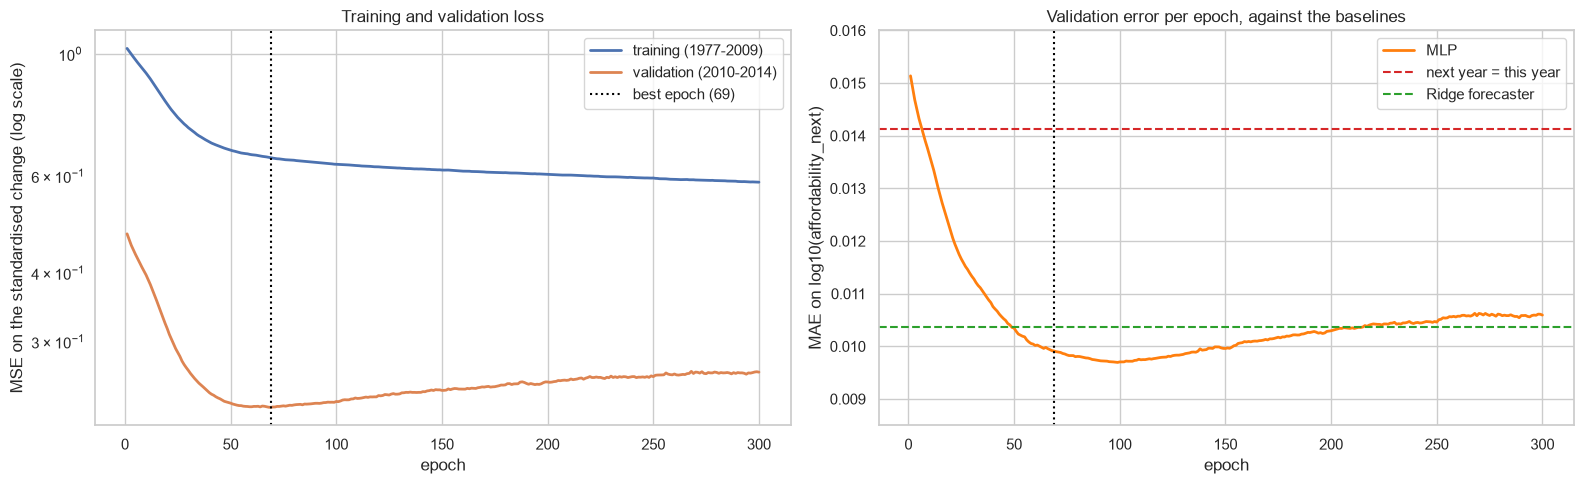

Validation MAE below 'next year = this year' from epoch 7, below Ridge from epoch 50; lowest validation MAE 0.0097 at epoch 99


,train_loss,val_loss,val_mae
epoch,,,
1,1.0231,0.4707,0.0151
10,0.9227,0.3962,0.0136
69,0.6476,0.2277,0.0099
150,0.6148,0.2444,0.0100
300,0.5844,0.2638,0.0106


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
history[["train_loss", "val_loss"]].plot(ax=axes[0], lw=2)
axes[0].axvline(best_epoch, color="black", ls=":", label=f"best epoch ({best_epoch})")
axes[0].set_yscale("log")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("MSE on the standardised change (log scale)")
axes[0].set_title("Training and validation loss")
axes[0].legend(["training (1977-2009)", "validation (2010-2014)", f"best epoch ({best_epoch})"])

axes[1].plot(history.index, history["val_mae"], lw=2, color="tab:orange", label="MLP")
for value, label, color in [(baseline_val.iloc[0, 0], "next year = this year", "tab:red"),
                            (baseline_val.iloc[1, 0], "Ridge forecaster", "tab:green")]:
    axes[1].axhline(value, ls="--", color=color, label=label)
axes[1].axvline(best_epoch, color="black", ls=":")
axes[1].set_ylim(0.0085, 0.016)
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("MAE on log10(affordability_next)")
axes[1].set_title("Validation error per epoch, against the baselines")
axes[1].legend()
plt.tight_layout()
save_fig("02_training_curves", also_model_card=True)
plt.show()
first_below = lambda value: int(history.index[history["val_mae"] < value][0])
print(f"Validation MAE below 'next year = this year' from epoch {first_below(baseline_val.iloc[0, 0])}, "
      f"below Ridge from epoch {first_below(baseline_val.iloc[1, 0])}; lowest validation MAE "
      f"{history['val_mae'].min():.4f} at epoch {history['val_mae'].idxmin()}")
history.iloc[[0, 9, best_epoch - 1, 149, len(history) - 1]]

How to read the curves:
- **It learns quickly, then slowly overfits.** The validation loss falls for about 70 epochs and reaches its lowest point at **epoch 69** (0.228); after that it creeps back up (0.264 at epoch 300) while the training loss keeps falling (from 1.02 to 0.58). That is the overfitting pattern of notebook 01: the network starts to fit details of 1977–2009 that do not carry over to 2010–2014. **We would stop around epoch 70**, and early stopping does exactly that: the weights of epoch 69 are restored.
- **The validation loss is lower than the training loss** throughout. This is not an error: the validation years 2010–2014 are calmer than the training years (section 1.3), so their changes are easier to forecast, and dropout is switched off when measuring validation.
- **Against the baselines (right):** the network beats "next year = this year" after about 7 epochs and the Ridge forecaster after about 50. Its best validation MAE is about **0.0097** (around epoch 100), against **0.0104** for Ridge, and at the restored epoch 69 it is **0.0099**. The loss we stop on (MSE) and the MAE we report disagree by a few epochs; the difference between them (0.0002) is smaller than the spread between random seeds (section 5).
- Without early stopping, after 300 epochs the validation MAE (0.0106) is **worse than Ridge**: stopping at the right time matters more than any other setting (section 5).

# 4. Look inside the network

The inspection tools of notebook 01, copied here unchanged: `parameter_table` (every weight matrix), `draw_network` (neurons and weights) and `layer_outputs` (what comes out of each layer for one example).

In [11]:
def parameter_table(model):
    # One row per weight matrix and bias vector: its shape, how many numbers it holds and their spread
    rows = []
    for name, p in model.named_parameters():
        values = p.detach().cpu().numpy()
        rows.append({"parameter": name, "shape": tuple(values.shape), "count": values.size,
                     "mean": values.mean(), "std": values.std(), "min": values.min(), "max": values.max()})
    return pd.DataFrame(rows).set_index("parameter")


def layer_outputs(model, x):
    # Pass x through a Sequential model one layer at a time and keep what comes out of each layer
    outputs = []
    with torch.no_grad():
        for name, layer in model.named_children():
            x = layer(x)
            outputs.append((f"{name}: {layer.__class__.__name__}", x.cpu()))
    return outputs


def draw_network(model, input_names=None, output_names=None, max_neurons=12, weight_scale=None, title=None, ax=None):
    # Notebook 01's drawing: circles are neurons, lines are weights (blue = positive, red = negative;
    # thicker and darker = larger). Wide layers only show their first `max_neurons` neurons.
    layers = list(model) if isinstance(model, nn.Sequential) else [model]
    linears = [layer for layer in layers if isinstance(layer, nn.Linear)]
    labels = []
    for layer in layers:
        if isinstance(layer, nn.Linear):
            labels.append(f"Linear {layer.in_features}→{layer.out_features}")
        elif not isinstance(layer, nn.Dropout) and labels:
            labels[-1] += f"\n+ {layer.__class__.__name__}"
    sizes = [linears[0].in_features] + [layer.out_features for layer in linears]
    shown = [min(n, max_neurons) for n in sizes]
    spacing = [min(2 / max(n - 1, 1), 0.6) for n in shown]
    ys = [(np.arange(n) - (n - 1) / 2) * -gap for n, gap in zip(shown, spacing)]
    if ax is None:
        fig, ax = plt.subplots(figsize=(2.8 * len(sizes) + 1, 6))
    for l, layer in enumerate(linears):
        W = layer.weight.detach().cpu().numpy()[:shown[l + 1], :shown[l]]
        scale = weight_scale or np.abs(W).max()
        for j, y_out in enumerate(ys[l + 1]):
            for i, y_in in enumerate(ys[l]):
                strength = min(abs(W[j, i]) / scale, 1)
                ax.plot([l, l + 1], [y_in, y_out], color="tab:blue" if W[j, i] > 0 else "tab:red",
                        lw=0.3 + 3 * strength, alpha=0.15 + 0.75 * strength, zorder=1)
    circle_size = np.clip(2500 / max(shown), 60, 700)
    for l, (n, yy) in enumerate(zip(sizes, ys)):
        ax.scatter(np.full(len(yy), l), yy, s=circle_size, color="lightgrey" if l == 0 else "white", edgecolors="black", zorder=2)
        if n > len(yy):
            ax.text(l, yy.min() - 0.12, f"+ {n - len(yy)} more", ha="center", va="top", fontsize=9)
        ax.text(l, -1.3, "Input" if l == 0 else labels[l - 1], ha="center", va="top", fontsize=10)
    for name, yy in zip(input_names or [], ys[0]):
        ax.text(-0.15, yy, name, ha="right", va="center", fontsize=9)
    for name, yy in zip(output_names or [], ys[-1]):
        ax.text(len(sizes) - 0.85, yy, name, ha="left", va="center", fontsize=9)
    n_params = sum(p.numel() for p in model.parameters())
    ax.set_title(title or f"{n_params:,} parameters")
    ax.set_xlim(-1, len(sizes) - 0.2)
    ax.set_ylim(-1.7, 1.2)
    ax.axis("off")
    return ax


pd.concat({"before training": parameter_table(mlp_untrained)[["shape", "count", "std", "min", "max"]],
           "after training": parameter_table(mlp)[["std", "min", "max"]]}, axis=1)

before training                              after training          \
                    shape count    std     min     max            std     min   
parameter                                                                       
0.weight         (32, 26)   832 0.1146 -0.1952  0.1960         0.1080 -0.2901   
0.bias              (32,)    32 0.1200 -0.1915  0.1863         0.1273 -0.1902   
3.weight         (32, 32)  1024 0.0998 -0.1754  0.1762         0.1001 -0.2294   
3.bias              (32,)    32 0.1049 -0.1685  0.1548         0.1018 -0.1846   
6.weight          (1, 32)    32 0.1141 -0.1688  0.1766         0.1430 -0.2041   
6.bias               (1,)     1 0.0000 -0.0566 -0.0566         0.0000 -0.0276   

                   
              max  
parameter          
0.weight   0.2865  
0.bias     0.2340  
3.weight   0.2531  
3.bias     0.1732  
6.weight   0.2503  
6.bias    -0.0276

Figure saved to ..\figures\03_network_before_after.png (and models/)


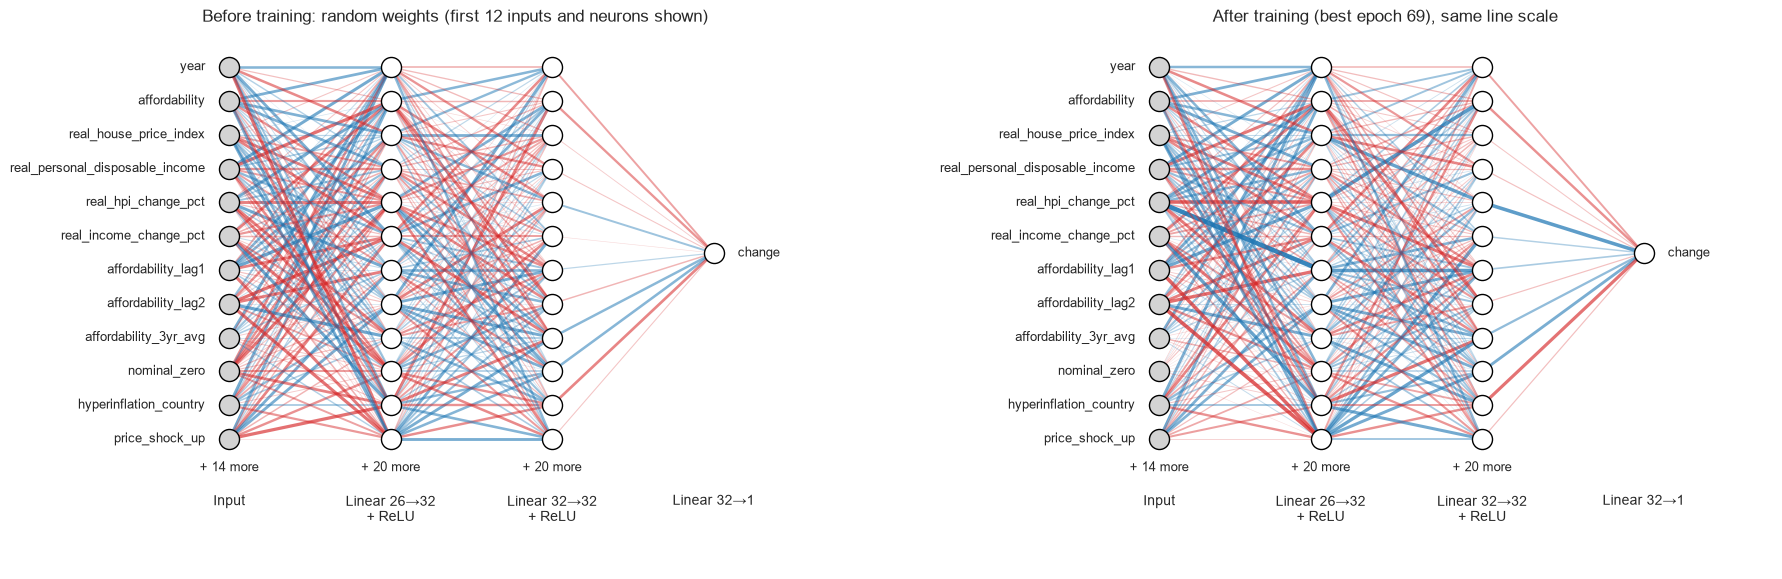

In [12]:
same_scale = max(layer.weight.abs().max().item() for layer in mlp if isinstance(layer, nn.Linear))
fig, axes = plt.subplots(1, 2, figsize=(22, 7))
draw_network(mlp_untrained, INPUT_NAMES, ["change"], weight_scale=same_scale, ax=axes[0],
             title="Before training: random weights (first 12 inputs and neurons shown)")
draw_network(mlp, INPUT_NAMES, ["change"], weight_scale=same_scale, ax=axes[1],
             title=f"After training (best epoch {best_epoch}), same line scale")
save_fig("03_network_before_after", also_model_card=True)
plt.show()

- The network has **1,953 parameters**: 26×32+32 = 864 in the first layer, 32×32+32 = 1,056 in the second and 32+1 = 33 in the output, about 2 per training row (820). That is small for a neural network, and a reason to regularise.
- **Training changed the weights only a little.** The spread (std) of the first layer's weights went from 0.115 to 0.108 and the largest weight from 0.20 to 0.29; the output layer moved most (std 0.114 → 0.143). With a small learning rate (1e-4), weight decay and only 69 epochs, the network stays close to its random start, which is part of why it does not overfit. A few thicker lines appear after training, for example from `real_hpi_change_pct` (this year's house price growth), the input that also mattered most for the Day 2 model after the level itself.
- ⚠️ As in notebook 01, a thick line is **not** a measure of importance: each input passes through 32 + 32 neurons and is mixed with all the others. To ask which input matters, permutation importance (used for the Ridge forecaster) is the right tool.

### One country-year through the network

We follow **Spain, 2012** (a validation year, in the middle of its house price correction) through the layers with `layer_outputs`: 26 scaled inputs go in, each hidden layer turns them into 32 numbers (after ReLU, many are 0), and the output neuron gives the standardised change, which we turn back into a forecast.

0: Linear   : shape (1, 32)
1: ReLU     : shape (1, 32)
2: Dropout  : shape (1, 32)
3: Linear   : shape (1, 32)
4: ReLU     : shape (1, 32)
5: Dropout  : shape (1, 32)
6: Linear   : shape (1, 1)


Figure saved to ..\figures\04_one_example_through_the_network.png (and models/)


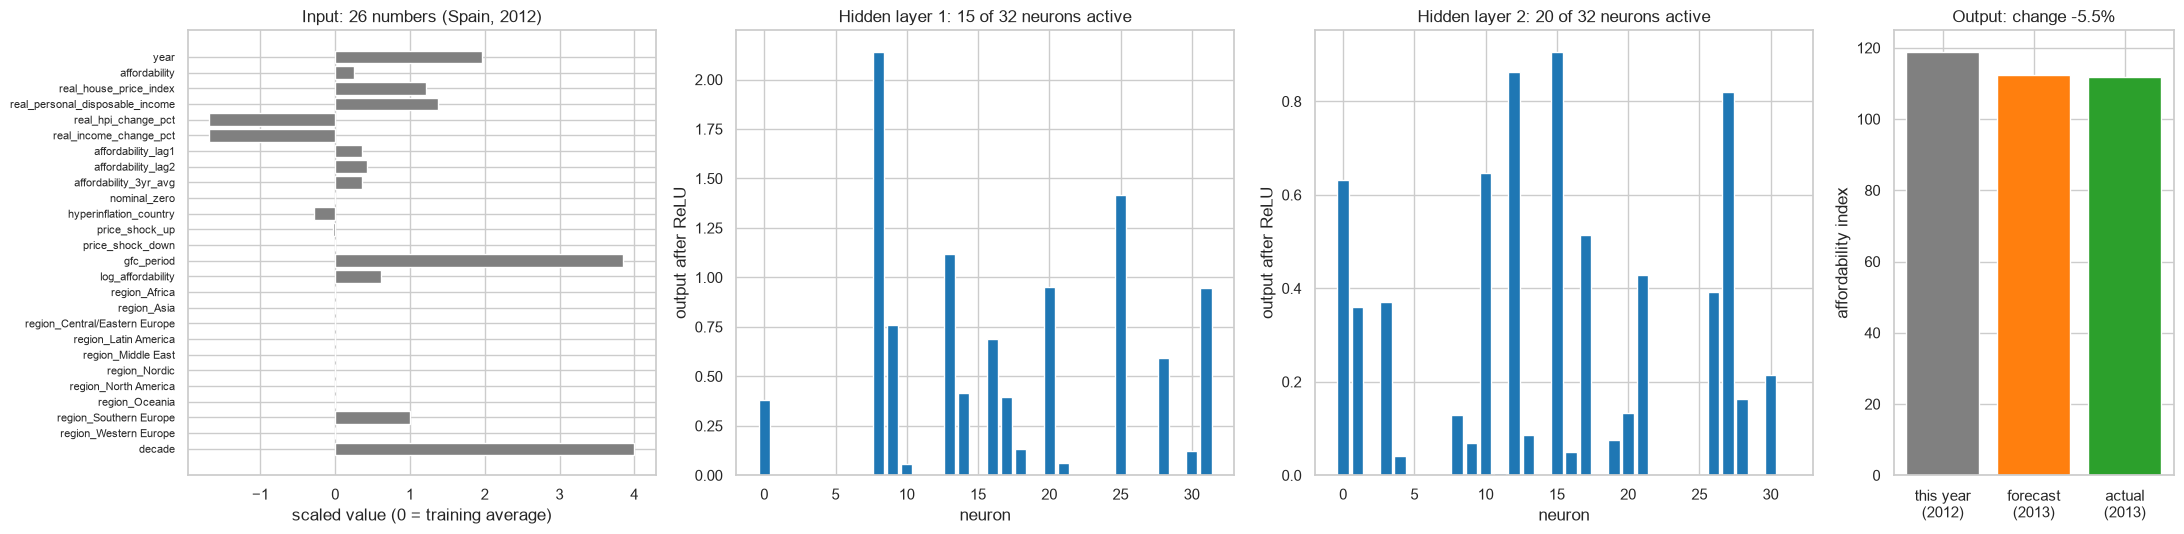

Spain 2012: affordability 118.9; network forecast for 2013: 112.4; actual: 111.9


In [13]:
row = df.index[(df["iso"] == "ESP") & (df["year"] == 2012)][0]
x_one = to_tensor(preprocess.transform(X.loc[[row]]))
steps = layer_outputs(mlp, x_one)
for name, output in steps:
    print(f"{name:<12}: shape {tuple(output.shape)}")

hidden_1, hidden_2, out = steps[1][1][0], steps[4][1][0], steps[6][1][0].item()
change_log = out * TARGET_STD + TARGET_MEAN
forecast = 10 ** (X.loc[row, "log_affordability"] + change_log)

fig, axes = plt.subplots(1, 4, figsize=(22, 5.5), gridspec_kw={"width_ratios": [1.5, 1.6, 1.6, 0.9]})
axes[0].barh(INPUT_NAMES, x_one[0].numpy(), color="grey")
axes[0].invert_yaxis()
axes[0].tick_params(axis="y", labelsize=8)
axes[0].set_xlabel("scaled value (0 = training average)")
axes[0].set_title("Input: 26 numbers (Spain, 2012)")
for ax, values, name in [(axes[1], hidden_1, "Hidden layer 1"), (axes[2], hidden_2, "Hidden layer 2")]:
    ax.bar(range(len(values)), values.numpy(), color="tab:blue")
    ax.set_xlabel("neuron")
    ax.set_ylabel("output after ReLU")
    ax.set_title(f"{name}: {(values > 0).sum()} of {len(values)} neurons active")
axes[3].bar(["this year\n(2012)", "forecast\n(2013)", "actual\n(2013)"],
            [df.loc[row, "affordability"], forecast, df.loc[row, "affordability_next"]], color=["grey", "tab:orange", "tab:green"])
axes[3].set_ylabel("affordability index")
axes[3].set_title(f"Output: change {(10 ** change_log - 1) * 100:+.1f}%")
plt.tight_layout()
save_fig("04_one_example_through_the_network", also_model_card=True)
plt.show()
print(f"Spain 2012: affordability {df.loc[row, 'affordability']:.1f}; network forecast for 2013: {forecast:.1f}; "
      f"actual: {df.loc[row, 'affordability_next']:.1f}")

- **Input:** Spain in 2012 had **falling** real house prices and **falling** real incomes (both about 1.7 standard deviations below the training average), the `gfc_period` flag on, and an affordability level slightly above the training average. (`decade` = 4 is not scaled: Day 2's preprocessing encodes the decade as 0 = 1970s … 4 = 2010s.)
- **Hidden layers:** only **15 of 32** neurons of the first layer and **20 of 32** of the second are active for this country-year; ReLU switches the others off. This pattern of active neurons is the network's own description of "a market in a correction".
- **Output:** a change of **−5.5%**, so a forecast of **112.4** for 2013, against an actual value of **111.9** (from 118.9 in 2012). "Next year = this year" would have said 118.9. The network has learned that falling prices and incomes tend to continue for one more year.

# 5. Tuning and regularisation

Each experiment changes **one thing** compared with the final model (residual target, 32-32, dropout 0.2 + weight decay 1e-3, learning rate 1e-4, early stopping with patience 30) and is compared on the **validation** years. To make sure a difference is not just luck of the random start, every variant is trained with **5 different seeds**, and we report the mean and spread of the validation MAE.

In [14]:
EXPERIMENTS = {
    "final model": {},
    "predict the level directly (not the change)": {"residual": False},
    "no dropout, no weight decay": {"dropout": 0.0, "weight_decay": 0.0},
    "no early stopping (300 epochs)": {"patience": None, "last_epoch": True},
    "learning rate 1e-3": {"lr": 1e-3},
    "smaller: one hidden layer of 16": {"hidden": 16, "layers": 1},
    "bigger: 64-64": {"hidden": 64},
}
SEEDS = [0, 1, 2, 3, 42]

rows = []
start = time.time()
for name, change in EXPERIMENTS.items():
    maes, epochs = [], []
    for seed in SEEDS:
        torch.manual_seed(seed)
        model = make_mlp(hidden=change.get("hidden", HIDDEN), dropout=change.get("dropout", DROPOUT),
                         layers=change.get("layers", 2))
        hist, best = train(model, lr=change.get("lr", LR), weight_decay=change.get("weight_decay", WEIGHT_DECAY),
                           patience=change.get("patience", PATIENCE), residual=change.get("residual", True), seed=seed)
        maes.append(hist["val_mae"].iloc[-1] if change.get("last_epoch") else hist.loc[best, "val_mae"])
        epochs.append(len(hist) if change.get("last_epoch") else best)
    rows.append({"experiment": name, "validation MAE (mean of 5 seeds)": np.mean(maes),
                 "spread (std)": np.std(maes), "epochs used (median)": int(np.median(epochs))})
experiments = pd.DataFrame(rows).set_index("experiment")
print(f"{len(EXPERIMENTS) * len(SEEDS)} trainings in {time.time() - start:.0f} s")
experiments

35 trainings in 349 s


,validation MAE (mean of 5 seeds),spread (std),epochs used (median)
experiment,,,
final model,0.0098,0.0001,69
predict the level directly (not the change),0.0154,0.0009,187
"no dropout, no weight decay",0.0099,0.0001,44
no early stopping (300 epochs),0.0105,0.0004,300
learning rate 1e-3,0.0099,0.0001,6
smaller: one hidden layer of 16,0.0099,0.0002,138
bigger: 64-64,0.0098,0.0002,41


Figure saved to ..\figures\05_experiments.png (and models/)


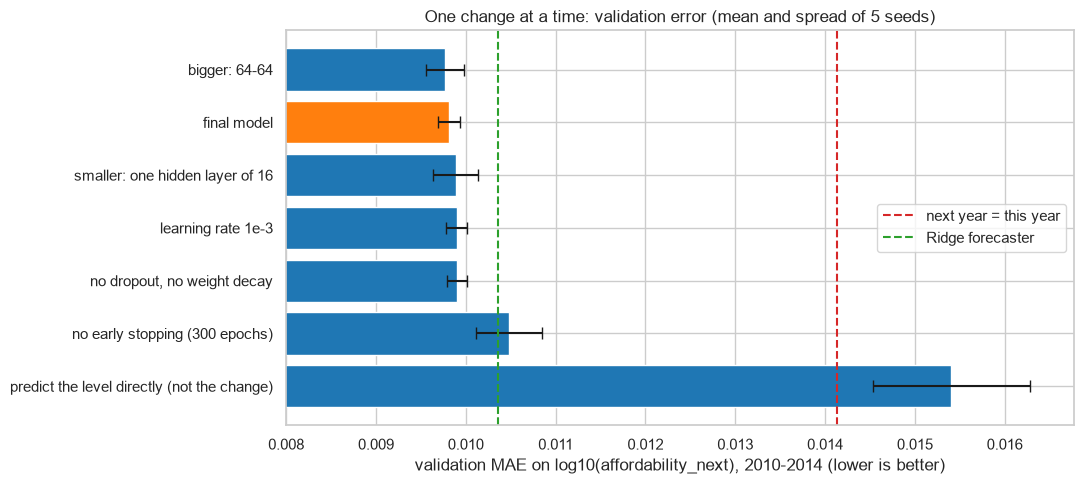

In [15]:
plot_data = experiments.sort_values("validation MAE (mean of 5 seeds)", ascending=False)
fig, ax = plt.subplots(figsize=(11, 5))
colors = ["tab:orange" if name == "final model" else "tab:blue" for name in plot_data.index]
ax.barh(plot_data.index, plot_data["validation MAE (mean of 5 seeds)"], xerr=plot_data["spread (std)"], capsize=4, color=colors)
for value, label, color in [(baseline_val.iloc[0, 0], "next year = this year", "tab:red"),
                            (baseline_val.iloc[1, 0], "Ridge forecaster", "tab:green")]:
    ax.axvline(value, ls="--", color=color, label=label)
ax.set_xlim(0.008, (plot_data["validation MAE (mean of 5 seeds)"] + plot_data["spread (std)"]).max() * 1.03)
ax.set_xlabel("validation MAE on log10(affordability_next), 2010-2014 (lower is better)")
ax.set_title("One change at a time: validation error (mean and spread of 5 seeds)")
ax.legend(loc="center right")
plt.tight_layout()
save_fig("05_experiments", also_model_card=True)
plt.show()

Reading the table (all on the validation years, mean of 5 seeds):
- **The one choice that matters: predict the change, not the level.** Predicting `log10(affordability_next)` directly gives **0.0154**, worse even than "next year = this year" (0.0141). The level ranges from about 1.6 to 2.8 in log10 across countries and decades, and the network has to rebuild it from scaled inputs, with errors of a few percent. Predicting the change makes "no change" the starting point, and the network only learns the correction: **0.0098**.
- **Early stopping is the second thing that matters:** without it (300 epochs), the error grows to **0.0105**, slightly worse than Ridge (0.0104).
- **Everything else makes no measurable difference.** Dropout + weight decay, the learning rate, a smaller (16) or bigger (64-64) network all land between **0.0098 and 0.0099**, within about one standard deviation of each other (0.0001–0.0002). With 820 training rows and a smooth relationship, the network size is not the limit; the information in the inputs is.
- We keep the **32-32 network with dropout and weight decay**: as good as the others, small, and less sensitive to the exact stopping epoch than the unregularised version (it reaches its best at epoch 69, not 44). The learning rate 1e-4 gives smooth curves; with 1e-3 the best epoch is reached after only **6** epochs, which makes early stopping fragile.

# 6. The test set, once

All choices are made. Now, and only now, we evaluate on **2015–2024**, the same test set as the Ridge forecaster, with the same metrics: R² on the log scale, MAE and RMSE in **index points**, and the share of forecasts within ±5%.

In [16]:
forecasts_log = {
    "Next year = this year": log_now["test"],
    "Ridge forecaster (trained 1977-2014)": ridge_main.predict(X[is_test]),
    "Ridge (trained 1977-2009, like the MLP)": ridge_fit.predict(X[is_test]),
    "MLP (this model)": predict_log(mlp, A["test"], log_now["test"]),
}
actual = 10 ** y_log["test"]
rows = {}
for name, pred_log in forecasts_log.items():
    pred = 10 ** pred_log
    pct = (pred - actual) / actual * 100
    rows[name] = {"MAE (index points)": mean_absolute_error(actual, pred), "RMSE (index points)": root_mean_squared_error(actual, pred),
                  "R² (log scale)": r2_score(y_log["test"], pred_log), "within ±5%": (np.abs(pct) <= 5).mean(),
                  "MAE (log10)": mean_absolute_error(y_log["test"], pred_log)}
test_results = pd.DataFrame(rows).T
test_results

,MAE (index points),RMSE (index points),R² (log scale),within ±5%,MAE (log10)
Next year = this year,3.7350,5.2555,0.7701,0.7538,0.0160
Ridge forecaster (trained 1977-2014),3.2810,4.7500,0.8255,0.8308,0.0137
"Ridge (trained 1977-2009, like the MLP)",3.2640,4.7401,0.8262,0.8154,0.0136
MLP (this model),3.2248,4.7425,0.8273,0.8115,0.0135


Figure saved to ..\figures\06_test_comparison.png (and models/)


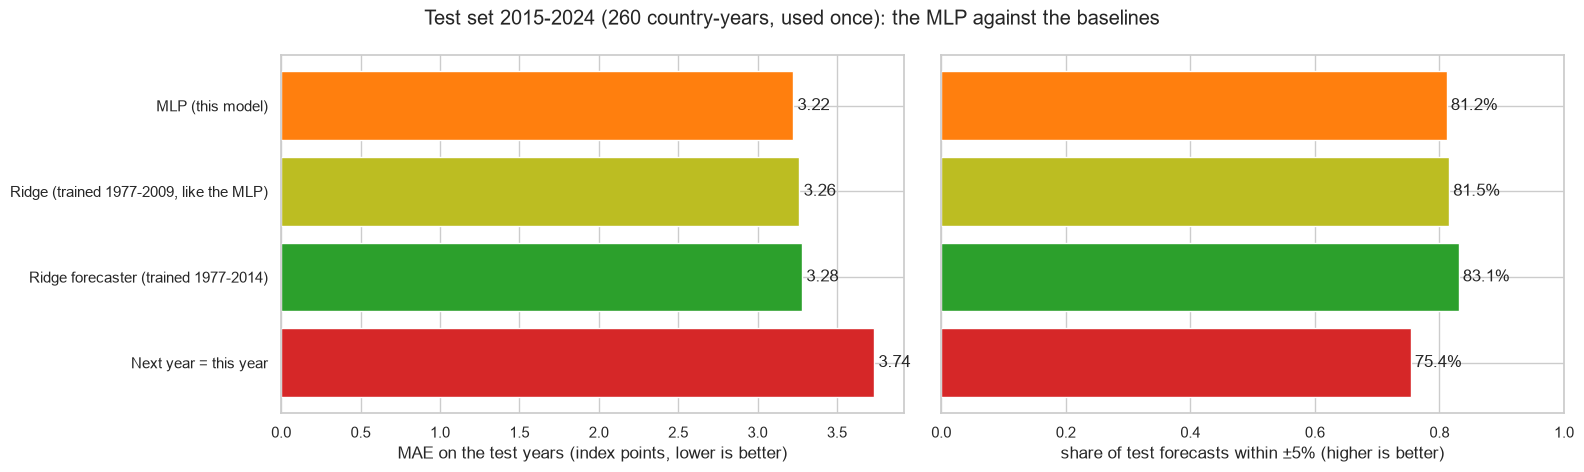

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
order = test_results.sort_values("MAE (index points)", ascending=False)
colors = {"Next year = this year": "tab:red", "Ridge forecaster (trained 1977-2014)": "tab:green",
          "Ridge (trained 1977-2009, like the MLP)": "tab:olive", "MLP (this model)": "tab:orange"}
for ax, column, label in [(axes[0], "MAE (index points)", "MAE on the test years (index points, lower is better)"),
                          (axes[1], "within ±5%", "share of test forecasts within ±5% (higher is better)")]:
    bars = ax.barh(order.index, order[column], color=[colors[n] for n in order.index])
    ax.bar_label(bars, labels=[f"{v:.2f}" if column.startswith("MAE") else f"{v:.1%}" for v in order[column]], padding=3)
    ax.set_xlabel(label)
axes[1].set_xlim(0, 1)
axes[1].set_yticklabels([])
fig.suptitle("Test set 2015-2024 (260 country-years, used once): the MLP against the baselines")
plt.tight_layout()
save_fig("06_test_comparison", also_model_card=True)
plt.show()

Figure saved to ..\figures\07_predicted_vs_actual.png (and models/)


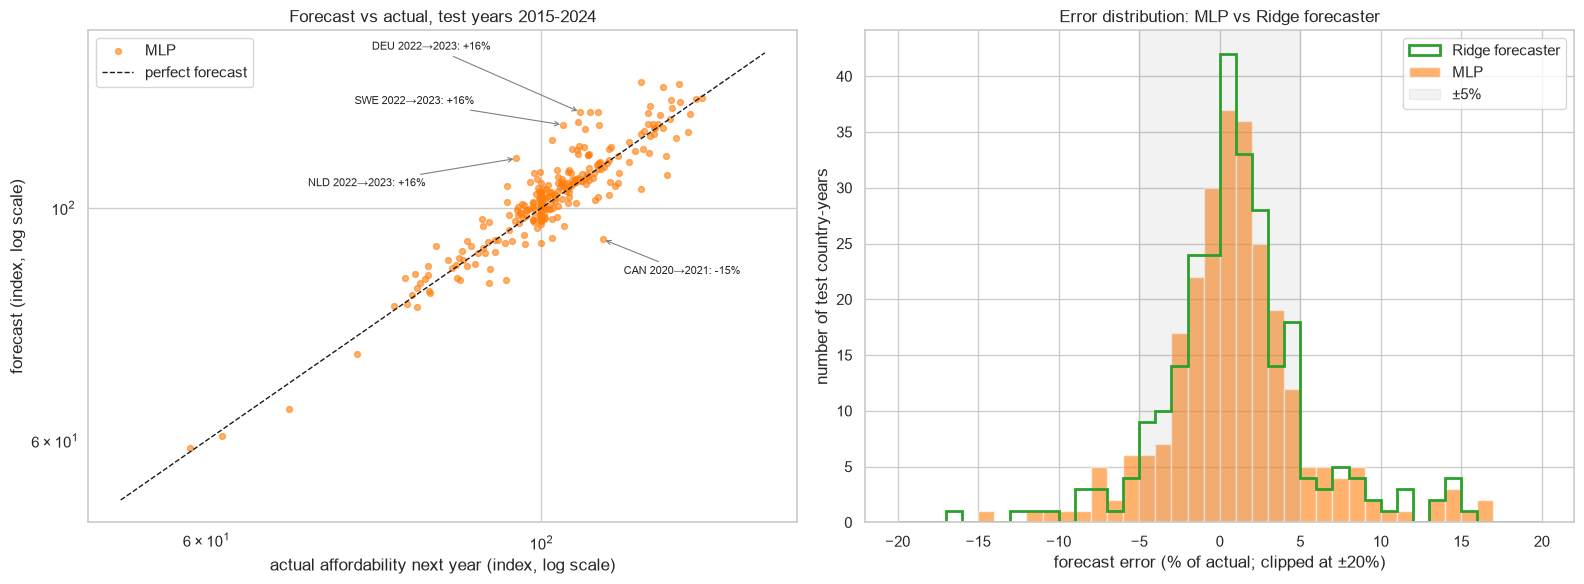

  MLP: within ±2%: 48.1%, within ±5%: 81.2%, above 10%: 13 of 260, median absolute error 2.06%
Ridge: within ±2%: 47.3%, within ±5%: 83.1%, above 10%: 15 of 260, median absolute error 2.09%


In [18]:
mlp_pred = 10 ** forecasts_log["MLP (this model)"]
ridge_pred = 10 ** forecasts_log["Ridge forecaster (trained 1977-2014)"]
test_rows = df[is_test].assign(mlp=mlp_pred, ridge=ridge_pred,
                               mlp_error_pct=(mlp_pred - actual) / actual * 100,
                               ridge_error_pct=(ridge_pred - actual) / actual * 100)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].scatter(actual, mlp_pred, s=18, alpha=0.6, color="tab:orange", label="MLP")
lims = [actual.min() * 0.9, actual.max() * 1.1]
axes[0].plot(lims, lims, "k--", lw=1, label="perfect forecast")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("actual affordability next year (index, log scale)")
axes[0].set_ylabel("forecast (index, log scale)")
axes[0].set_title("Forecast vs actual, test years 2015-2024")
worst = test_rows.reindex(test_rows["mlp_error_pct"].abs().sort_values(ascending=False).index).head(4)
for r, offset in zip(worst.itertuples(), [(-150, 45), (-150, 15), (-150, -20), (15, -25)]):    # labels spread out, with arrows
    axes[0].annotate(f"{r.iso} {r.year}→{r.year + 1}: {r.mlp_error_pct:+.0f}%", (r.affordability_next, r.mlp),
                     xytext=offset, textcoords="offset points", fontsize=8,
                     arrowprops=dict(arrowstyle="->", lw=0.8, color="grey"))
axes[0].legend()

bins = np.linspace(-20, 20, 41)
axes[1].hist(test_rows["ridge_error_pct"].clip(-20, 20), bins=bins, histtype="step", lw=2, color="tab:green", label="Ridge forecaster")
axes[1].hist(test_rows["mlp_error_pct"].clip(-20, 20), bins=bins, alpha=0.6, color="tab:orange", label="MLP")
axes[1].axvspan(-5, 5, color="grey", alpha=0.1, label="±5%")
axes[1].set_xlabel("forecast error (% of actual; clipped at ±20%)")
axes[1].set_ylabel("number of test country-years")
axes[1].set_title("Error distribution: MLP vs Ridge forecaster")
axes[1].legend()
plt.tight_layout()
save_fig("07_predicted_vs_actual", also_model_card=True)
plt.show()
for name, column in [("MLP", "mlp_error_pct"), ("Ridge", "ridge_error_pct")]:
    e = test_rows[column].abs()
    print(f"{name:>5}: within ±2%: {(e <= 2).mean():.1%}, within ±5%: {(e <= 5).mean():.1%}, "
          f"above 10%: {(e > 10).sum()} of {len(e)}, median absolute error {e.median():.2f}%")

## 6.1 Where does it fail?

The average hides the misses that matter for an early warning. We look at the error **per country** and at the **largest misses**.

Figure saved to ..\figures\08_failures.png (and models/)


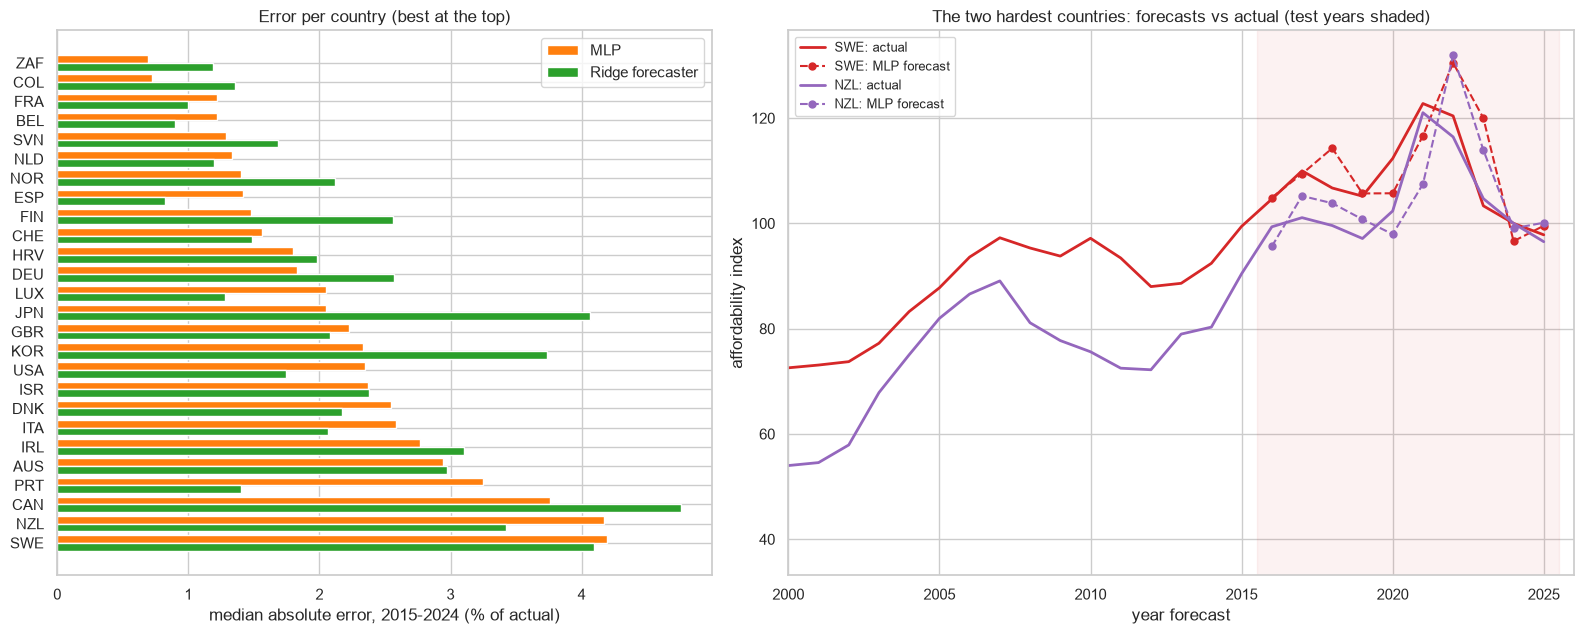

,iso,year,affordability,affordability_next,mlp,mlp_error_pct,ridge_error_pct,real_hpi_change_pct,real_income_change_pct
1137,DEU,2022,123.3000,106.1000,123.4000,16.3000,14.1000,-0.7000,1.0000
1155,SWE,2022,120.4000,103.3000,120.0000,16.1000,15.7000,-1.6000,0.4000
1150,NLD,2022,107.2000,96.3000,111.5000,15.8000,14.0000,5.5000,-0.1000
1082,CAN,2020,89.3000,109.8000,93.4000,-15.0000,-16.1000,7.0000,7.0000
1148,KOR,2022,121.9000,107.7000,123.4000,14.6000,14.4000,2.1000,1.4000
1134,CAN,2022,117.6000,105.7000,120.8000,14.3000,13.0000,4.8000,-2.1000
1110,COL,2021,118.1000,101.6000,116.1000,14.2000,13.8000,-1.5000,4.4000
1126,NZL,2021,121.0000,116.4000,131.9000,13.3000,14.5000,24.2000,5.1000


In [19]:
by_country = (test_rows.assign(mlp_abs=test_rows["mlp_error_pct"].abs(), ridge_abs=test_rows["ridge_error_pct"].abs())
              .groupby("iso")[["mlp_abs", "ridge_abs"]].median().sort_values("mlp_abs"))

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.2]})
yy = np.arange(len(by_country))
axes[0].barh(yy - 0.2, by_country["mlp_abs"], height=0.4, color="tab:orange", label="MLP")
axes[0].barh(yy + 0.2, by_country["ridge_abs"], height=0.4, color="tab:green", label="Ridge forecaster")
axes[0].set_yticks(yy, by_country.index)
axes[0].invert_yaxis()
axes[0].set_xlabel("median absolute error, 2015-2024 (% of actual)")
axes[0].set_title("Error per country (best at the top)")
axes[0].legend()

for iso, color in [(by_country.index[-1], "tab:red"), (by_country.index[-2], "tab:purple")]:
    part = df[df["iso"] == iso].set_index("year")
    t = test_rows[test_rows["iso"] == iso].set_index("year")
    axes[1].plot(part.index + 1, part["affordability_next"], color=color, lw=2, label=f"{iso}: actual")
    axes[1].plot(t.index + 1, t["mlp"], "o--", color=color, ms=5, label=f"{iso}: MLP forecast")
axes[1].axvspan(2015.5, 2025.5, color="tab:red", alpha=0.06)
axes[1].set_xlim(2000, 2026)
axes[1].set_xlabel("year forecast")
axes[1].set_ylabel("affordability index")
axes[1].set_title("The two hardest countries: forecasts vs actual (test years shaded)")
axes[1].legend(fontsize=9)
plt.tight_layout()
save_fig("08_failures", also_model_card=True)
plt.show()

cols = ["iso", "year", "affordability", "affordability_next", "mlp", "mlp_error_pct", "ridge_error_pct", "real_hpi_change_pct", "real_income_change_pct"]
test_rows.reindex(test_rows["mlp_error_pct"].abs().sort_values(ascending=False).index)[cols].head(8).round(1)

In [20]:
# The error per forecast year: are the misses spread out, or concentrated in a few years?
by_year = test_rows.assign(forecast_year=test_rows["year"] + 1, mlp_abs=test_rows["mlp_error_pct"].abs(),
                           ridge_abs=test_rows["ridge_error_pct"].abs(),
                           actual_change=(test_rows["affordability_next"] / test_rows["affordability"] - 1) * 100)
by_year.groupby("forecast_year").agg(
    MLP_mean_abs_error_pct=("mlp_abs", "mean"), Ridge_mean_abs_error_pct=("ridge_abs", "mean"),
    MLP_mean_error_pct=("mlp_error_pct", "mean"), mean_actual_change_pct=("actual_change", "mean"),
    MLP_misses_over_10pct=("mlp_abs", lambda s: int((s > 10).sum()))).round(1)

,MLP_mean_abs_error_pct,Ridge_mean_abs_error_pct,MLP_mean_error_pct,mean_actual_change_pct,MLP_misses_over_10pct
forecast_year,,,,,
2016,1.8000,1.8000,-0.2000,2.3000,0
2017,1.4000,1.6000,0.5000,1.8000,0
2018,2.6000,2.6000,2.1000,-0.0000,1
2019,2.3000,2.4000,1.5000,-0.2000,0
2020,3.0000,3.0000,-1.5000,2.8000,0
2021,4.0000,4.4000,-1.7000,4.9000,2
2022,4.7000,4.5000,2.6000,1.5000,3
2023,7.2000,7.0000,7.1000,-5.4000,6
2024,2.1000,2.2000,0.1000,-1.8000,0


## 6.2 Errors by housing-market regime

Our clustering analysis (step 3) placed every country-year in one of **four market regimes**: *affordable steady growth*, *price boom*, *expensive plateau* and *price correction*. Here we use those labels to ask **in which phase of the market the forecasts fail**: the regime of the year the forecast is made from.

⚠️ The regimes are used **only to group the test errors**, not as an input to the network. They were built with each country's average over the **whole** period 1977–2024 ("expensive compared with its own history"), so as an input they would leak information from the future into the forecast. The model is unchanged.

Figure saved to ..\figures\10_errors_by_regime.png (and models/)


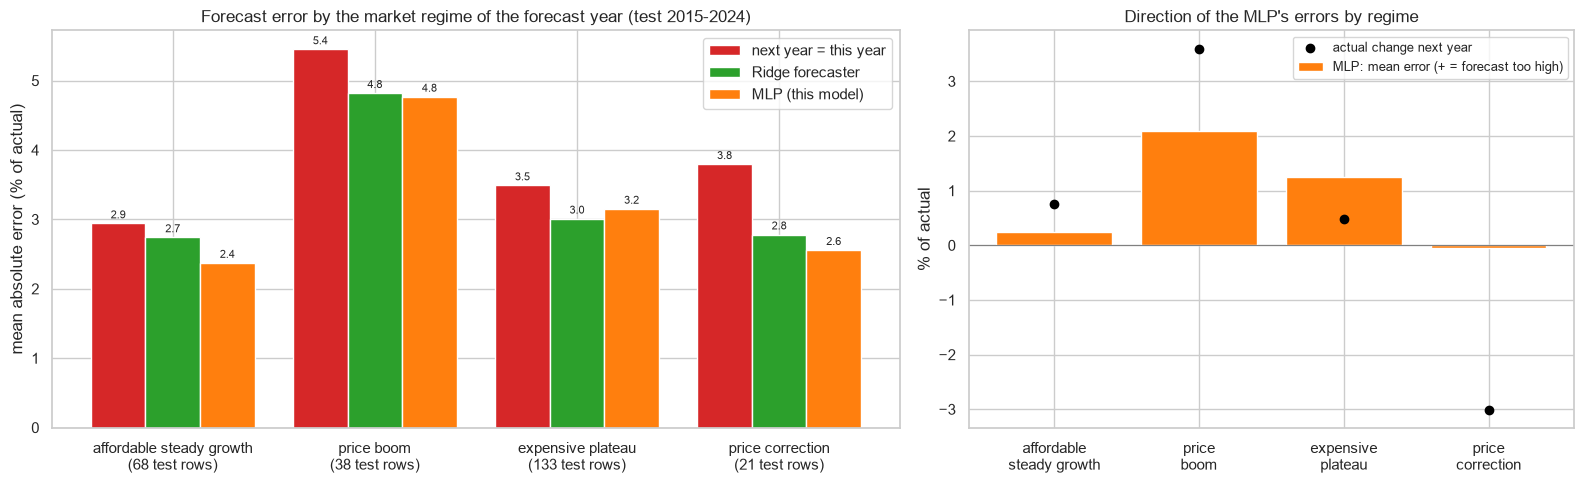

,test_rows,actual_change_next_year_pct,persistence_abs_error_pct,ridge_abs_error_pct,mlp_abs_error_pct,mlp_mean_error_pct,mlp_within_5pct
cluster_name,,,,,,,
affordable steady growth,68,0.7500,2.9410,2.7400,2.3720,0.2380,0.8820
price boom,38,3.6000,5.4490,4.8180,4.7660,2.0910,0.6320
expensive plateau,133,0.4840,3.4890,3.0090,3.1510,1.2570,0.8200
price correction,21,-3.0050,3.7950,2.7810,2.5570,-0.0520,0.8570


In [21]:
REGIME_URL = "https://huggingface.co/datasets/iaac-maai/day3-group8-housing-market-regimes/resolve/main/housing_market_regimes.csv"
REGIME_FILE = DATA_DIR / "housing_market_regimes.csv"
if not REGIME_FILE.exists():
    urllib.request.urlretrieve(REGIME_URL, REGIME_FILE)
regimes = pd.read_csv(REGIME_FILE)[["iso", "year", "cluster", "cluster_name"]]

REGIME_ORDER = ["affordable steady growth", "price boom", "expensive plateau", "price correction"]
with_regime = test_rows.merge(regimes, on=["iso", "year"], how="left", validate="one_to_one")
assert with_regime["cluster_name"].notna().all(), "every test country-year has a regime"
with_regime["persistence_error_pct"] = (with_regime["affordability"] - with_regime["affordability_next"]) / with_regime["affordability_next"] * 100
with_regime["actual_change_pct"] = (with_regime["affordability_next"] / with_regime["affordability"] - 1) * 100

by_regime = with_regime.groupby("cluster_name").agg(
    test_rows=("iso", "size"),
    actual_change_next_year_pct=("actual_change_pct", "mean"),
    persistence_abs_error_pct=("persistence_error_pct", lambda s: s.abs().mean()),
    ridge_abs_error_pct=("ridge_error_pct", lambda s: s.abs().mean()),
    mlp_abs_error_pct=("mlp_error_pct", lambda s: s.abs().mean()),
    mlp_mean_error_pct=("mlp_error_pct", "mean"),
    mlp_within_5pct=("mlp_error_pct", lambda s: (s.abs() <= 5).mean()),
).reindex(REGIME_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.4, 1]})
xs = np.arange(len(REGIME_ORDER))
for offset, column, label, color in [(-0.27, "persistence_abs_error_pct", "next year = this year", "tab:red"),
                                     (0.0, "ridge_abs_error_pct", "Ridge forecaster", "tab:green"),
                                     (0.27, "mlp_abs_error_pct", "MLP (this model)", "tab:orange")]:
    bars = axes[0].bar(xs + offset, by_regime[column], width=0.27, color=color, label=label)
    axes[0].bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
axes[0].set_xticks(xs, [f"{name}\n({n} test rows)" for name, n in zip(REGIME_ORDER, by_regime["test_rows"])])
axes[0].set_ylabel("mean absolute error (% of actual)")
axes[0].set_title("Forecast error by the market regime of the forecast year (test 2015-2024)")
axes[0].legend()

axes[1].bar(xs, by_regime["mlp_mean_error_pct"], color="tab:orange", label="MLP: mean error (+ = forecast too high)")
axes[1].scatter(xs, by_regime["actual_change_next_year_pct"], color="black", zorder=3, label="actual change next year")
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set_xticks(xs, [name.replace(" ", "\n", 1) for name in REGIME_ORDER])
axes[1].set_ylabel("% of actual")
axes[1].set_title("Direction of the MLP's errors by regime")
axes[1].legend(fontsize=9)
plt.tight_layout()
save_fig("10_errors_by_regime", also_model_card=True)
plt.show()
by_regime.round(3)

Reading the figure and the table (mean absolute error, % of actual):

| Regime of the forecast year | Test rows | Next year = this year | Ridge forecaster | **MLP** | MLP within ±5% |
|---|---|---|---|---|---|
| Affordable steady growth | 68 | 2.9 | 2.7 | **2.4** | 88% |
| Price boom | 38 | 5.4 | 4.8 | **4.8** | **63%** |
| Expensive plateau | 133 | 3.5 | **3.0** | 3.2 | 82% |
| Price correction | 21 | 3.8 | 2.8 | **2.6** | 86% |

- **Booms are the hardest phase to forecast**, for every model: the MLP's error is twice as large as in steady-growth years (4.8% vs 2.4%), and only **63%** of its boom forecasts are within ±5% (82–88% in the other regimes). After a boom year affordability worsens by 3.6% on average, but the network forecasts even more (mean error **+2.1%**): it expects booms to continue harder than they do.
- **Corrections are forecast well** (2.6%, against 3.8% for "next year = this year"): once prices fall, they tend to keep falling for another year, and both models have learned that momentum. Most of these test rows are the corrections of 2023–2024.
- **The expensive plateau** (the most common regime since 2010, 133 test rows) is the only one where the Ridge forecaster is slightly better (3.0% vs 3.2%), and the MLP's errors lean upwards (+1.3%). Four of the network's eight largest misses start from a plateau year: Germany, Sweden and the Netherlands in 2022, Canada in 2020. A plateau looks calm in the data, yet several of the sharp 2021 and 2023 turns started from one.
- The differences between the MLP and Ridge **within** each regime are small (0.0–0.4 points) and rest on 21–133 rows: they confirm the overall tie rather than a real advantage. What the regimes add is **where to be careful**: a forecast made in a boom year, or from an expensive plateau just before a shock, deserves the most scrutiny.

**The headline: on the test years, the network ties with our Ridge forecaster; it is not clearly better.**

| Test 2015–2024 | MAE (index points) | R² (log) | Within ±5% |
|---|---|---|---|
| Next year = this year | 3.74 | 0.770 | 75.4% |
| Ridge forecaster | 3.28 | 0.826 | **83.1%** |
| **MLP** | **3.22** | **0.827** | 81.2% |

- The MLP's MAE is **1.7% lower** than Ridge (3.22 vs 3.28 index points) and its R² is 0.001 higher, but it has **fewer** forecasts within ±5% (81.2% vs 83.1%, i.e. 211 vs 216 of 260) and practically the same RMSE (4.74 vs 4.75). The same Ridge trained only on 1977–2009, like the network, scores 3.26. These differences are smaller than what changes with a different random seed or a few years more or less: **the honest conclusion is a draw**. Both beat "next year = this year" (by 14% for the MLP, 12% for Ridge).
- **The error distributions (figure 7, right) are almost identical:** median absolute error **2.06%** (MLP) vs **2.09%** (Ridge); within ±2%: 48.1% vs 47.3%; misses above 10%: **13 vs 15** of 260. Ridge has a few more forecasts in the ±5% band, the network a few fewer large misses.
- **Where it fails: 2021–2023.** The misses are not spread over the years. In forecasts for **2023**, the mean absolute error jumps to **7.2%** (Ridge 7.0%), with **6** of the 13 misses above 10%. On average affordability **improved** by 5.4% that year (the year after interest rates rose sharply, which is not in our inputs), but the network forecast it to stay about level or get worse (mean error +7.1%). The 2022 indicators gave little warning: in the largest misses (Germany, Sweden, the Netherlands, South Korea, Canada), real prices in 2022 were still rising or only 1–2% down, so the network, like Ridge, forecast roughly "more of the same", and affordability then fell by 10–14%. In **2021** it made the opposite mistake: the pandemic housing boom (affordability +4.9% on average) came without warning in the 2020 data, so it under-forecast (Canada 2020→2021: −15%). In calm years (2016–2019, 2024–2025) the mean absolute error is **1.4–2.6%**.
- **Per country** (figure 8, left), the network is best for South Africa and Colombia (median error below 1%) and worst for **Sweden, New Zealand and Canada** (about 4%), markets with sharp turns. It is clearly better than Ridge for Japan and Korea, and clearly worse for Spain and Portugal: the two models are not better or worse everywhere, they make **different small mistakes and the same big ones**: all 8 of the network's largest misses (14–16%) are also misses of 13–16% for Ridge.

**What the misses have in common:** a **turning point caused by something that is not in the inputs**: interest rates (2022–2023), the pandemic (2020–2021). No model trained on these 17 columns can see them coming; a more flexible model does not help.

# 7. Application: forecasts for hand-made scenarios

The use case: an analyst takes a country's latest indicators and asks "what happens next year if…?". We start from **Spain in 2024** (the last year in the data) and change the house price growth of 2024, keeping incomes fixed: prices that fell 5%, the actual 2024 values, and prices that rose 5%, 10% and 15% faster. When house prices change, the house price index, affordability (and its log) change with them. Both models answer, so we can see whether they agree.

Figure saved to ..\figures\09_scenarios_spain.png (and models/)


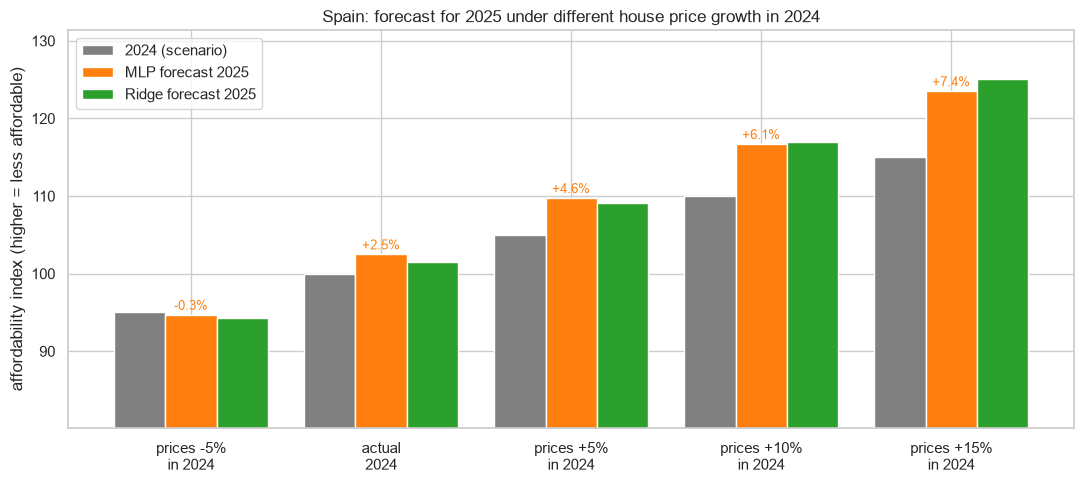

,affordability 2024,MLP forecast 2025,Ridge forecast 2025,MLP: change next year
extra price growth in 2024,,,,
-5%,95.0000,94.7000,94.3000,-0.3000
+0%,100.0000,102.5000,101.5000,2.5000
+5%,105.0000,109.8000,109.1000,4.6000
+10%,110.0000,116.7000,116.9000,6.1000
+15%,115.0000,123.5000,125.1000,7.4000


In [22]:
base = X[(df["iso"] == "ESP") & (df["year"] == 2024)].copy()
scenarios = []
for extra in [-5, 0, 5, 10, 15]:
    s = base.copy()
    factor = 1 + extra / 100
    s["real_house_price_index"] *= factor
    s["affordability"] *= factor
    s["log_affordability"] = np.log10(s["affordability"])
    s["real_hpi_change_pct"] += extra
    s_a = to_tensor(preprocess.transform(s))
    scenarios.append({"extra price growth in 2024": f"{extra:+d}%", "affordability 2024": s["affordability"].item(),
                      "MLP forecast 2025": 10 ** predict_log(mlp, s_a, s["log_affordability"].to_numpy())[0],
                      "Ridge forecast 2025": 10 ** ridge_main.predict(s)[0]})
scenarios = pd.DataFrame(scenarios).set_index("extra price growth in 2024")
scenarios["MLP: change next year"] = (scenarios["MLP forecast 2025"] / scenarios["affordability 2024"] - 1) * 100

fig, ax = plt.subplots(figsize=(11, 5))
xs = np.arange(len(scenarios))
ax.bar(xs - 0.27, scenarios["affordability 2024"], width=0.27, color="grey", label="2024 (scenario)")
ax.bar(xs, scenarios["MLP forecast 2025"], width=0.27, color="tab:orange", label="MLP forecast 2025")
ax.bar(xs + 0.27, scenarios["Ridge forecast 2025"], width=0.27, color="tab:green", label="Ridge forecast 2025")
ax.set_xticks(xs, [f"prices {i}\nin 2024" if i != "+0%" else "actual\n2024" for i in scenarios.index])
ax.set_ylabel("affordability index (higher = less affordable)")
levels = scenarios[["affordability 2024", "MLP forecast 2025", "Ridge forecast 2025"]]
ax.set_ylim(levels.min().min() * 0.85, levels.max().max() * 1.05)
for x, (_, r) in zip(xs, scenarios.iterrows()):
    ax.text(x, r["MLP forecast 2025"] + 0.6, f"{r['MLP: change next year']:+.1f}%", ha="center", fontsize=9, color="tab:orange")
ax.set_title("Spain: forecast for 2025 under different house price growth in 2024")
ax.legend()
plt.tight_layout()
save_fig("09_scenarios_spain", also_model_card=True)
plt.show()
scenarios.round(1)

- With Spain's **actual** 2024 indicators, the network forecasts a deterioration of **+2.5%** for 2025 (Ridge: +1.5%).
- **Both models translate faster price growth into a worse forecast** (momentum), and they agree closely for moderate scenarios: prices +10% in 2024 gives **116.7** (MLP) and **116.9** (Ridge).
- **The difference is at the extremes.** Ridge is linear, so every extra 5% of price growth adds about the same amount. The network's response **flattens**: the extra change next year goes +2.5%, +4.6%, +6.1%, +7.4% for 0, +5, +10, +15% extra price growth, so at +15% it forecasts 123.5 against Ridge's 125.1. This bend is the only visible effect of the network's non-linearity, and the test set says it is neither clearly better nor worse.
- ⚠️ These are **what-if** forecasts from historical patterns, not predictions of what Spain will do: the model does not know interest rates, supply, or policy.

# 8. Save, reload and use

A PyTorch `state_dict` holds only the numbers, so a user needs three things: the **weights** (`model.pt`), the **preprocessing** (`scaler.joblib`) and the **code that builds the network** (in the model card). Our `scaler.joblib` is a small dictionary with the fitted `ColumnTransformer`, the column order, and the mean and standard deviation of the target change, everything needed to turn a row of raw indicators into a forecast.

In [23]:
torch.save(mlp.state_dict(), MODEL_DIR / "model.pt")
joblib.dump({"preprocess": preprocess, "columns": FEATURE_COLS,
             "target_mean": TARGET_MEAN, "target_std": TARGET_STD}, MODEL_DIR / "scaler.joblib")

# Reload as a user would: rebuild the architecture, load the weights and the preprocessing
reloaded = nn.Sequential(
    nn.Linear(26, 32), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(32, 32), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(32, 1),
)
reloaded.load_state_dict(torch.load(MODEL_DIR / "model.pt", map_location="cpu"))
reloaded.eval()
bundle = joblib.load(MODEL_DIR / "scaler.joblib")

example = X[(df["iso"] == "ESP") & (df["year"] == 2024)][bundle["columns"]]       # one row, raw columns
x_new = torch.tensor(bundle["preprocess"].transform(example), dtype=torch.float32)
with torch.no_grad():
    change = reloaded(x_new).item() * bundle["target_std"] + bundle["target_mean"]
forecast_2025 = 10 ** (np.log10(example["affordability"].item()) + change)
print(f"Spain 2024: {example['affordability'].item():.1f} -> forecast 2025: {forecast_2025:.1f} "
      f"(same as before saving: {np.isclose(forecast_2025, scenarios.loc['+0%', 'MLP forecast 2025'])})")
print("Files for Hugging Face:", sorted(p.name for p in MODEL_DIR.iterdir()))

Spain 2024: 100.0 -> forecast 2025: 102.5 (same as before saving: True)
Files for Hugging Face: ['02_training_curves.png', '03_network_before_after.png', '04_one_example_through_the_network.png', '05_experiments.png', '06_test_comparison.png', '07_predicted_vs_actual.png', '08_failures.png', '09_scenarios_spain.png', '10_errors_by_regime.png', 'README.md', 'model.pt', 'scaler.joblib']


# 9. Conclusions

### Key findings
- **A small MLP (26 → 32 → 32 → 1, 1,953 parameters)** trained in about 10 seconds on a laptop CPU forecasts next year's affordability with a test MAE of **3.22 index points** (R² 0.827 on the log scale, 81% of forecasts within ±5%).
- **It ties with our Ridge forecaster** (3.28 index points, R² 0.826, 83% within ±5%): 1.7% lower MAE, but fewer forecasts within ±5%. Both beat "next year = this year" (3.74) by 12–14%. **The network is not better than the linear model**: on a small table with a smooth relationship, as notebook 01 found for the energy classes.
- **Predicting the change instead of the level was the decisive design choice** (validation MAE 0.0098 vs 0.0154); **early stopping** came second (0.0098 vs 0.0105 without). Dropout, weight decay, learning rate and network size made no measurable difference.
- **By market regime** (from our clustering analysis), **booms are the hardest phase**: 4.8% mean error and only 63% of forecasts within ±5%, against 2.4% in affordable steady growth; corrections are forecast well (2.6%).
- **The errors are concentrated in 2021–2023** (up to 7.2% mean absolute error for forecasts of 2023, against 1.4–2.6% in calm years): the pandemic boom and the interest-rate correction were not foreseeable from these indicators. Both models make the same large misses.

### Limitations and biases
- **Missing drivers:** no interest rates, credit, supply, construction or migration data. The model extrapolates momentum and **misses turning points**, exactly when an early warning is most needed. Never read "no deterioration forecast" as "no risk".
- **Indexes, not levels:** affordability is an index with 2024 = 100 for every country, so the model says nothing about which country is more affordable.
- **Small data:** 820 training rows (26 countries × 33 years) and 260 test rows; differences of a few percent between models are within noise.
- **Coverage:** 26 mostly high-income countries, national averages only (a city boom can hide in a calm national average); the early years of South Korea, Israel and Croatia are the least reliable (data cleaning).
- **Not to be used for:** investment decisions, forecasts more than one year ahead, countries or regions not in the data, ranking countries, or any decision about individual households or properties.

### Next steps
- Add **interest rates and credit growth**: the one input that would have explained 2022–2023, for any model.
- Keep Ridge as the reference: a forecast that only a neural network can produce, and that Ridge disagrees with, should be checked rather than trusted.